# A Hybrid and Explainable Architecture for Early Sepsis Phenotyping and Prediction

## François Zapletal

This notebook implements a full pipeline completly reproductible for sepsis early prediction using MIMIC-III data.

1. **Device setup** : detect available hardware (DirectML / CUDA / CPU)
2. **Encoding pipeline** : SAITS imputation, TS2Vec embedding, Autoencoder compression
3. **Data loading** : load pre-computed encoded representations
4. **Detection Model** : Soft Phenotype Clustering (Attention based gating) + MoE Classifier

Source modules: src/processor.py, src/embedder.py, src/phenotype_moe.py

Input: data/mimic3_wide_clean.csv, adapted in memory to the existing pipeline.
First chronological ICU stay per SUBJECT_ID; rows without SepsisLabel excluded.
Only mapped physiological measurements enter the pipeline (no outcome columns or derived scores).
Representations: data/mimic3/sepsis_processed_full.npz. Models: models/mimic3/.

In [1]:
# The libraires that you have to download

# pip install torch torchvision torchaudio torch-directml
# pip install pypots
# pip install scikit-learn pandas numpy matplotlib seaborn scipy

In [2]:
import sys
sys.path.insert(0, 'src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools

import torch
import torch_directml

from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy.special import softmax

from embedder import SepsisEncodingPipeline
from phenotype_moe import PhenotypeMoE, train_phenotype_moe, evaluate_phenotype_moe_plus

c:\Travail\Recherche_A5\Research_Project_Early_Sepsis_Phenotyping_Prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



████████╗██╗███╗   ███╗███████╗    ███████╗███████╗██████╗ ██╗███████╗███████╗    █████╗ ██╗
╚══██╔══╝██║████╗ ████║██╔════╝    ██╔════╝██╔════╝██╔══██╗██║██╔════╝██╔════╝   ██╔══██╗██║
   ██║   ██║██╔████╔██║█████╗█████╗███████╗█████╗  ██████╔╝██║█████╗  ███████╗   ███████║██║
   ██║   ██║██║╚██╔╝██║██╔══╝╚════╝╚════██║██╔══╝  ██╔══██╗██║██╔══╝  ╚════██║   ██╔══██║██║
   ██║   ██║██║ ╚═╝ ██║███████╗    ███████║███████╗██║  ██║██║███████╗███████║██╗██║  ██║██║
   ╚═╝   ╚═╝╚═╝     ╚═╝╚══════╝    ╚══════╝╚══════╝╚═╝  ╚═╝╚═╝╚══════╝╚══════╝╚═╝╚═╝  ╚═╝╚═╝
ai4ts v0.0.3 - building AI for unified time-series analysis, https://time-series.ai 



## 1. Device Setup

Detect available hardware for PyTorch acceleration.

In [3]:
if torch_directml.is_available():
    device_dml = torch_directml.device()
    print(f"GPU detected: {torch_directml.device_name(0)}")
else:
    device_dml = torch.device("cpu")
    print("DirectML not available, falling back to CPU.")

GPU detected: AMD Radeon RX 6600M 


## 2. Encoding Pipeline

Run the full SAITS + TS2Vec + Autoencoder pipeline.
- **Base pipeline** : window [-2, +3] (same parameters as main.ipynb; includes post-onset hours), used for prediction

To reuse pre-trained models, pass them as arguments to pipeline.run(saits_model=..., ...). 

Run the adaptation setup before loading saved representations. Physiological analysis also requires df_filtered from the matching pipeline run.

In [4]:
# Preparation du CSV : noms physiologiques conserves.
from io import StringIO
from pathlib import Path

project_root = Path.cwd() if (Path.cwd() / 'data').is_dir() else Path.cwd().parent
mimic_output = project_root / 'data' / 'mimic3'
mimic_models = project_root / 'models' / 'mimic3'
physio_cols = """heartrate tempc sysbp diasbp meanbp resprate spo2 glucose etco2
ph pco2 po2 fio2 aado2 baseexcess bicarbonate_bg totalco2 chloride_bg calcium_bg
glucose_bg hematocrit_bg hemoglobin_bg so2 carboxyhemoglobin methemoglobin
potassium_bg sodium_bg temperature_bg albumin aniongap bicarbonate bilirubin
bilirubin_direct bilirubin_indirect bun calcium chloride creatinine glucose_lab
hematocrit hemoglobin inr lactate magnesium phosphate platelet potassium ptt sodium
wbc alt alp ast amylase ck_cpk ck_mb ggt ldh lipase fibrinogen pt d_dimer thrombin
troponin_i troponin_t ntprobnp crp mch mchc mcv rbc rdw neutrophils_pct
lymphocytes_pct monocytes_pct eosinophils_pct basophils_pct bands neutrophils_abs
lymphocytes_abs monocytes_abs urineoutput icp""".split()
df_mimic = pd.read_csv(project_root / 'data' / 'mimic3_wide_clean.csv',
                       usecols=['SUBJECT_ID', 'ICUSTAY_ID', 'INTIME', 'hr', 'SepsisLabel'] + physio_cols)

# Premier sejour par personne pour ne pas melanger ses sejours entre les splits.
first_stays = (df_mimic[['SUBJECT_ID', 'ICUSTAY_ID', 'INTIME']].drop_duplicates()
               .sort_values(['INTIME', 'ICUSTAY_ID']).drop_duplicates('SUBJECT_ID'))
df_mimic = df_mimic.merge(first_stays, on=['SUBJECT_ID', 'ICUSTAY_ID', 'INTIME'], validate='many_to_one')
df_mimic = (df_mimic[['SUBJECT_ID', 'hr', 'SepsisLabel'] + physio_cols]
            .rename(columns={'SUBJECT_ID': 'Patient_ID', 'hr': 'Hour'})
            .dropna(subset=['Patient_ID', 'Hour', 'SepsisLabel'])
            .sort_values(['Patient_ID', 'Hour']).reset_index(drop=True))
if not df_mimic['SepsisLabel'].isin([0, 1]).all():
    raise ValueError('SepsisLabel doit contenir uniquement 0 et 1.')
if df_mimic.duplicated(['Patient_ID', 'Hour']).any():
    raise ValueError('Doublons (Patient_ID, Hour) dans le CSV adapte.')
# Le pipeline attend un CSV : on lui passe le DataFrame en memoire, sans fichier.
mimic_csv = StringIO(df_mimic.to_csv(index=False))
print(f'DataFrame adapte : {df_mimic.shape}, {df_mimic.Patient_ID.nunique()} patients')
df_mimic.head()


DataFrame adapte : (3621326, 86), 38160 patients


,Patient_ID,Hour,SepsisLabel,heartrate,tempc,sysbp,diasbp,meanbp,resprate,spo2,...,lymphocytes_pct,monocytes_pct,eosinophils_pct,basophils_pct,bands,neutrophils_abs,lymphocytes_abs,monocytes_abs,urineoutput,icp
0,3,0,0.0,143.00,NaN,119.750000,45.250000,107.866681,NaN,78.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
1,3,1,0.0,155.75,NaN,83.625000,47.125000,60.125000,17.75,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
2,3,2,0.0,139.50,NaN,85.125000,44.375000,59.291663,15.00,97.666667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
3,3,3,0.0,125.50,NaN,126.666667,67.666667,90.666667,13.00,100.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
4,3,4,0.0,143.00,NaN,88.000000,55.000000,67.000000,17.50,99.500000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN


In [5]:
pipeline = SepsisEncodingPipeline(
    file_path=mimic_csv,
    window_start=-17+15,
    window_end=-6+9,
    min_presence_pct=0.5,
    validation_split=0.2,
    test_split=0.2,
    essential_cols=None,
    saits_epochs=10,
    saits_batch_size=32,
    ts2vec_output_dims=32,
    ts2vec_epochs=30,
    ts2vec_batch_size=32,
    ae_latent_dim=32,
    ae_epochs=50,
    ae_batch_size=64,
    ae_lr=1e-3,
    device=device_dml,
    random_state=42
)
mimic_csv.seek(0)
df_filtered, data_out, models_out, step_representations = pipeline.run()

saits_trained, ts2vec_trained, ae_trained = models_out

print("Saving models...")
SepsisEncodingPipeline.save_model(saits_trained, str(mimic_models / 'saits_model_base.pth'))
SepsisEncodingPipeline.save_model(ts2vec_trained, str(mimic_models / 'ts2vec_model_base.pth'))
SepsisEncodingPipeline.save_model(ae_trained, str(mimic_models / 'autoencoder_model_base.pth'))

Step 1: Data preparation and train/test split
Loading data from <_io.StringIO object at 0x000001D3A48F7AC0>...
Nb patients : 38160
Sepsis patients retained (window [-2, 3] inclusive): 6385
Non-sepsis patients retained (ratio 1.0): 6385
Non-physiological variables removed: 2 columns dropped.


KeyboardInterrupt: 

In [ ]:
df_filtered.info()

<class 'pandas.DataFrame'>
RangeIndex: 76620 entries, 0 to 76619
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   meanbp            70940 non-null  float64
 1   sysbp             71083 non-null  float64
 2   diasbp            71060 non-null  float64
 3   spo2              70008 non-null  float64
 4   Hour              76620 non-null  int64  
 5   will_have_sepsis  76620 non-null  float64
 6   resprate          71505 non-null  float64
 7   urineoutput       76620 non-null  float64
 8   Patient_ID        76620 non-null  int64  
 9   heartrate         72966 non-null  float64
dtypes: float64(8), int64(2)
memory usage: 5.8 MB


In [ ]:
# Sauvegarde propre ? MIMIC-III, s?par?e des r?sultats de main.ipynb.
pipeline.save_processed_data(data_out, folder=str(mimic_output))

Data saved to: c:\Travail\Recherche_A5\Research_Project_Early_Sepsis_Phenotyping_Prediction\data\mimic3\sepsis_processed_full.npz


## 3. Load Pre-Computed Representations

If the encoding pipeline has already been run and saved, load from disk directly.

In [ ]:
# Recharger uniquement les repr?sentations MIMIC-III.
data_out = SepsisEncodingPipeline.load_processed_data(
    filepath=str(mimic_output / 'sepsis_processed_full.npz'))

Data loaded.
Available arrays: ['X_train_encoded', 'X_val_encoded', 'X_test_encoded', 'y_train', 'y_val', 'y_test', 'X_train_pids', 'X_val_pids', 'X_test_pids']


## 4. Detection Model : Soft Phenotype Clustering + MoE Classifier

This stage takes the frozen patient embeddings produced by the encoding pipeline and trains, in a single run, two components:

Prototype gating (soft clustering) and Expert bank (MoE Classifier) 
Everything is optimized together with one optimizer and a single constant weighting (no warmup, no prototype re-initialization):


Epoch  10 | total 2.2412 | pred 0.6353 | cluster(ent+comp+marg) 0.6144 | balance 0.0281 | val AUROC 0.6769 | g_bar [0.2  0.31 0.3  0.18]
Epoch  20 | total 2.1935 | pred 0.6258 | cluster(ent+comp+marg) 0.5756 | balance 0.0284 | val AUROC 0.6798 | g_bar [0.24 0.27 0.3  0.2 ]
Epoch  30 | total 2.1447 | pred 0.6174 | cluster(ent+comp+marg) 0.5367 | balance 0.0241 | val AUROC 0.6778 | g_bar [0.26 0.28 0.27 0.19]
Epoch  40 | total 2.1125 | pred 0.6115 | cluster(ent+comp+marg) 0.5064 | balance 0.0247 | val AUROC 0.6823 | g_bar [0.29 0.23 0.27 0.2 ]
Epoch  50 | total 2.0726 | pred 0.6046 | cluster(ent+comp+marg) 0.4544 | balance 0.0316 | val AUROC 0.6797 | g_bar [0.24 0.25 0.28 0.23]
Epoch  60 | total 2.0427 | pred 0.5991 | cluster(ent+comp+marg) 0.4154 | balance 0.0377 | val AUROC 0.6718 | g_bar [0.24 0.32 0.22 0.22]
Early stopping at epoch 67 (no improvement for 20 epochs).
--- Validation ---
      DIAGNOSTIC GLOBAL : Phenotype MoE

[Rapport de Classification]
              precision    reca

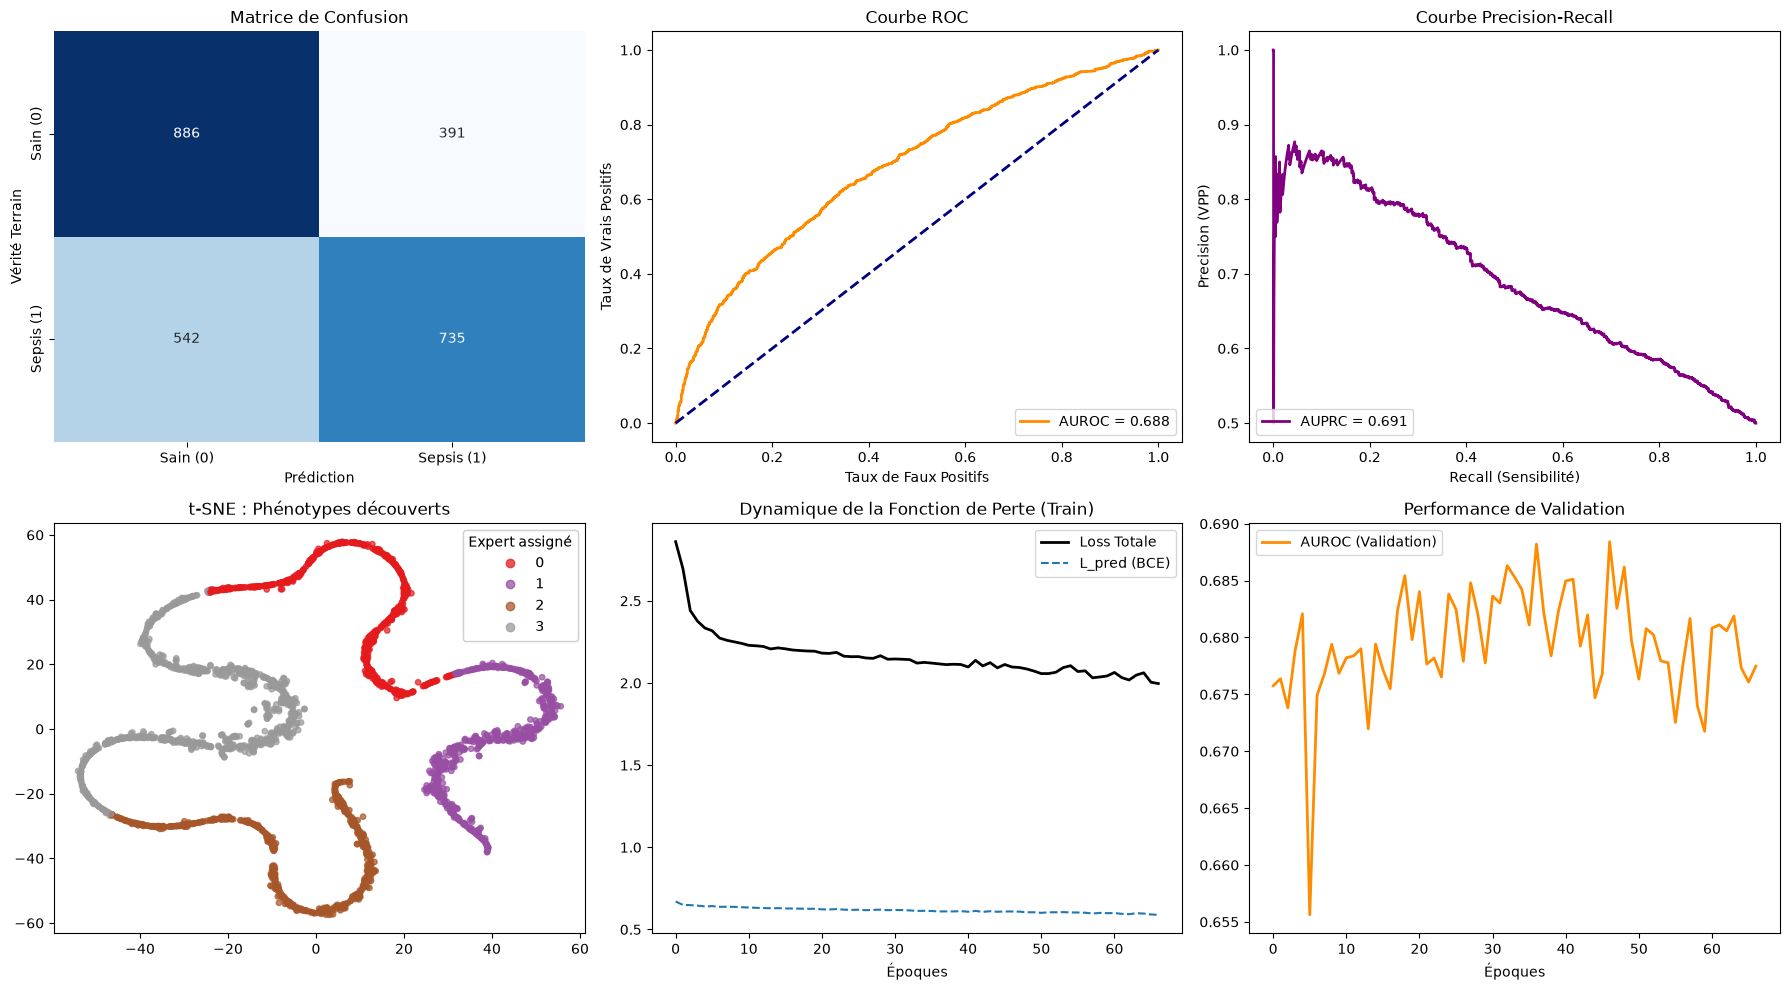

In [ ]:


X_tr, X_va, X_te, y_tr, y_va, y_te, pid_train, pid_val, pid_test = data_out

z_train = torch.tensor(X_tr, dtype=torch.float32)
z_val   = torch.tensor(X_va, dtype=torch.float32)
z_test  = torch.tensor(X_te, dtype=torch.float32)
y_train = torch.tensor(y_tr, dtype=torch.float32)
y_val = torch.tensor(y_va, dtype=torch.float32)
y_test  = torch.tensor(y_te, dtype=torch.float32)

model = PhenotypeMoE(input_dim=z_train.shape[1], n_clusters=4, temperature=0.3, margin=0.5)

model, history = train_phenotype_moe(
    model, z_train, y_train, z_val, y_val,
    epochs=200, batch_size=64, lr=1e-3,
    lambdas={'pred': 3.0, 'cluster': 0.5, 'balance': 0.0},
    patience=20, device=device_dml, verbose_every=10
)

print("--- Validation ---")
val_results = evaluate_phenotype_moe_plus(model, z_val, y_val, history, threshold=0.5, device=device_dml)


In [ ]:

print("--- Test ---")
test_results = evaluate_phenotype_moe_plus(model, z_test, y_test, threshold=0.5, device=device_dml)

--- Test ---


AttributeError: 'XGBClassifier' object has no attribute 'eval'

             n  sepsis_count  sepsis_rate  predicted_positive_rate  mean_probability
0        557.0         298.0     0.535009                 0.614004          0.537075
1        593.0         389.0     0.655986                 0.870152          0.692511
2        578.0         255.0     0.441176                 0.230104          0.401226
3        826.0         335.0     0.405569                 0.186441          0.370757
Global  2554.0        1277.0     0.500000                 0.448316          0.488631


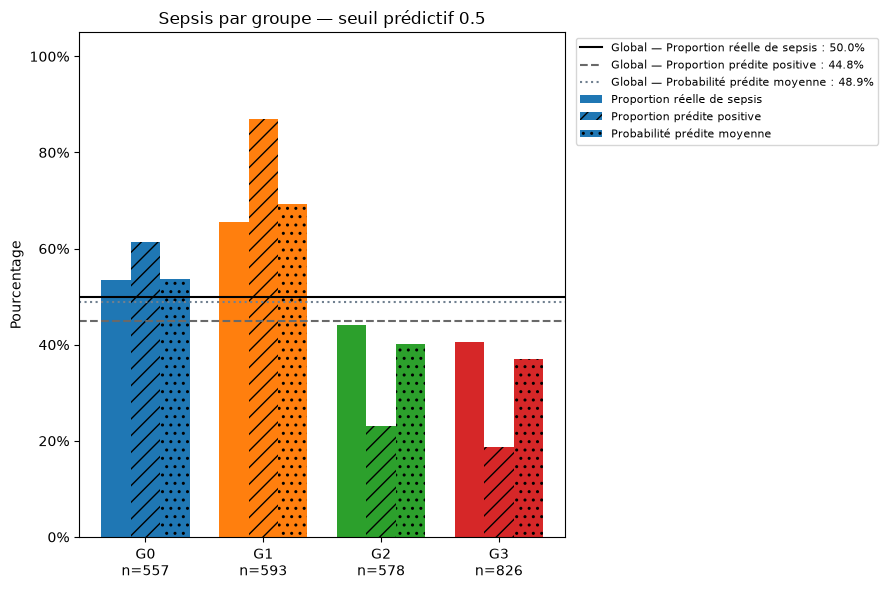

Médiane [Q1–Q3] des médianes individuelles :
                          G0                G1                G2                G3            Global
variable                                                                                           
meanbp         70 [64.3–77]    75.3 [67.7–85]      74 [68–80.1]    85 [76.5–94.6]  76.5 [68.6–85.5]
sysbp         113 [104–127]    113 [99.9–128]     114 [104–123]     130 [116–144]     118 [105–132]
diasbp       50 [44.8–55.5]  60.5 [52.5–69.3]      58 [52–64.9]    66.5 [58.5–74]      59 [51.5–68]
spo2            99 [98–100]      97 [95–98.5]    96.5 [95–97.5]      97.5 [96–99]      97.5 [96–99]
resprate       16 [14–18.5]  22.5 [19.5–26.5]  19.5 [17.5–22.2]    18 [15.5–20.5]      18.6 [16–22]
urineoutput  332 [62.5–760]       240 [0–750]       240 [0–800]  450 [0–1.22e+03]       315 [0–880]
heartrate      80 [69–89.5]     106 [100–116]    74.8 [68.2–81]        84 [74–91]    84.5 [73.5–97]

Couverture des patients (%) :
                      G

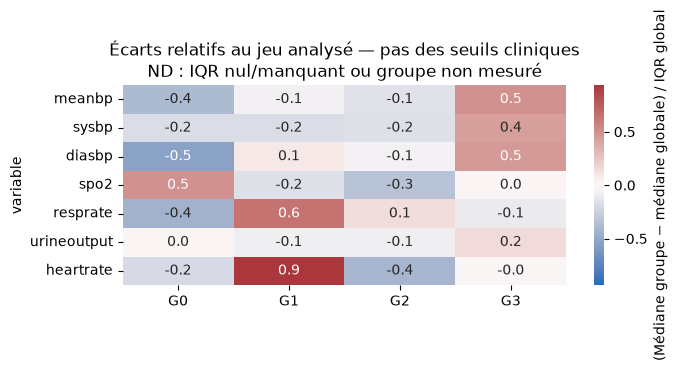

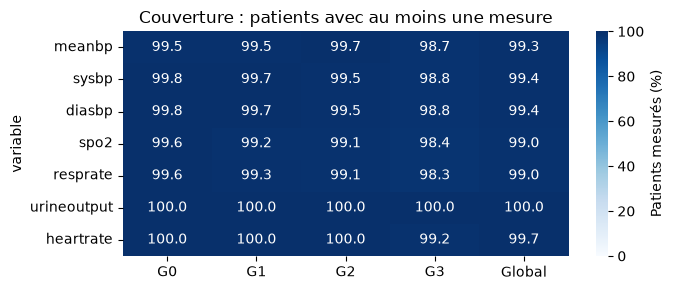

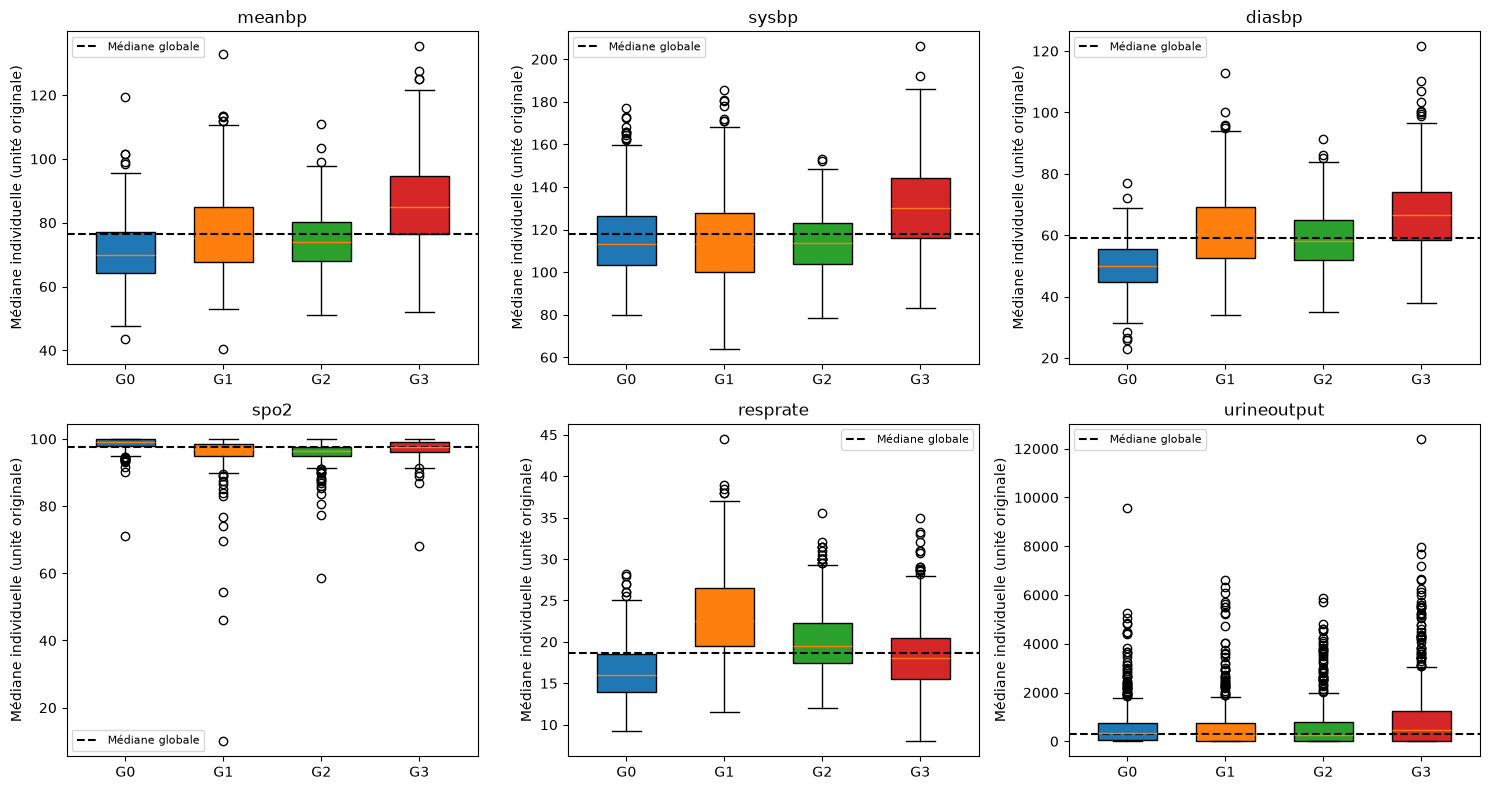

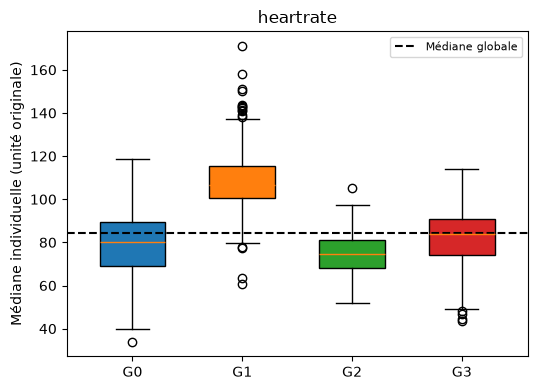

In [ ]:
from model_analysis import analyze_cluster_sepsis_rates, analyze_cluster_physiology
rates = analyze_cluster_sepsis_rates(model, z_test, y_test, pid_test, df_filtered, device=device_dml)

physiology = analyze_cluster_physiology(model, z_test, y_test, pid_test, df_filtered, device=device_dml)

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)
results = []

for name, (X_train, X_val, X_test) in \
        step_representations.items():
    print(name, X_train.shape)

    xgb_model = XGBClassifier(
        n_estimators=500,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=5,
        objective="binary:logistic",
        eval_metric="auc",
        early_stopping_rounds=30,
        tree_method="hist",
        random_state=42,
        n_jobs=4
    )

    xgb_model.fit(
        X_train, y_tr,
        eval_set=[(X_val, y_va)],
        verbose=False
    )
    print(
        f"{name} | "
        f"Best iteration: {xgb_model.best_iteration} | "
        f"Trees used: {xgb_model.best_iteration + 1}"
    )

    p_train = xgb_model.predict_proba(X_train)[:, 1]
    p_val = xgb_model.predict_proba(X_val)[:, 1]
    p_test = xgb_model.predict_proba(X_test)[:, 1]

    results.append({
        "Representation": name,
        "AUROC_train": roc_auc_score(y_tr, p_train),
        "AUROC_val": roc_auc_score(y_va, p_val),
        "AUROC_test": roc_auc_score(y_te, p_test),
        "AUPRC_test": average_precision_score(y_te, p_test)
    })

import pandas as pd

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

raw (7662, 42)
raw | Best iteration: 491 | Trees used: 492
saits (7662, 42)
saits | Best iteration: 496 | Trees used: 497
ts2vec (7662, 192)
ts2vec | Best iteration: 329 | Trees used: 330
autoencoder (7662, 32)
autoencoder | Best iteration: 237 | Trees used: 238
Representation  AUROC_train  AUROC_val  AUROC_test  AUPRC_test
           raw       0.8318     0.7548      0.7431      0.7272
         saits       0.8188     0.7498      0.7328      0.7127
        ts2vec       0.8018     0.6979      0.6713      0.6598
   autoencoder       0.7576     0.6921      0.6693      0.6599
